In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, confusion_matrix, recall_score
import joblib
%matplotlib inline
sns.set_style("whitegrid")


In [27]:
fiche_projet= {
    "Objectif métier": "détecter et réduire la fraude",
    "Questions de données": "identifier les schémas et typologie de fraude ",
    "Variable cible(y)": "churn (0 = légitime, 1 = frauduleux )",
    "Type de problème" : "classification binaire",
    "Critère de succès":"identifier au moins 80% des clients à risque",}
df_fiche= pd.DataFrame(list(fiche_projet.items()), columns=["Element","Description"])
df_fiche
   

,Element,Description
0,Objectif métier,détecter et réduire la fraude
1,Questions de données,identifier les schémas et typologie de fraude
2,Variable cible(y),"churn (0 = légitime, 1 = frauduleux )"
3,Type de problème,classification binaire
4,Critère de succès,identifier au moins 80% des clients à risque


In [28]:
fraud_data= pd.read_csv("C:/Users/USER/projet_detection_fraud/Fraud.csv/Fraud.csv")
print(fraud_data)

         step      type      amount     nameOrig  oldbalanceOrg  \
0           1   PAYMENT     9839.64  C1231006815      170136.00   
1           1   PAYMENT     1864.28  C1666544295       21249.00   
2           1  TRANSFER      181.00  C1305486145         181.00   
3           1  CASH_OUT      181.00   C840083671         181.00   
4           1   PAYMENT    11668.14  C2048537720       41554.00   
...       ...       ...         ...          ...            ...   
6362615   743  CASH_OUT   339682.13   C786484425      339682.13   
6362616   743  TRANSFER  6311409.28  C1529008245     6311409.28   
6362617   743  CASH_OUT  6311409.28  C1162922333     6311409.28   
6362618   743  TRANSFER   850002.52  C1685995037      850002.52   
6362619   743  CASH_OUT   850002.52  C1280323807      850002.52   

         newbalanceOrig     nameDest  oldbalanceDest  newbalanceDest  isFraud  \
0             160296.36  M1979787155            0.00            0.00        0   
1              19384.72  M2044282

In [29]:
fraud_data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [30]:
fraud_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [31]:
fraud_data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


ANALYSE EXPLORATOIRE DES DONNEES ( EDA)

In [32]:
#Compte des nbres de transactions normales(0) et des transactions frauduleuses (1)
print('---Repartition des transactions---')
print(fraud_data['isFraud'].value_counts())

---Repartition des transactions---
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [33]:
#Voir le pourcentage de fraude
print('\n---Pourcentage de fraude---')
print(fraud_data['isFraud'].value_counts(normalize=True)*100)


---Pourcentage de fraude---
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


99% des transactions légitimes constituent l'ensemble des opérations

In [34]:
#Comparaison du montant moyen des transactions normales vs les transactions frauduleuses
print('---Montant moyen le statut de fraude---')
print(fraud_data.groupby('isFraud')['amount'].mean())


---Montant moyen le statut de fraude---
isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64


constat majeur : Les transactions frauduleuses (isFraud = 1) présentent un montant moyen nettement plus élevé que les transactions légitimes (isFraud = 0).
Transactions légitimes : ~178 197 € en moyenne.
Transactions frauduleuses : ~1 467 967 € en moyenne (soit environ 8 fois plus).

In [35]:
type_fraud= pd.crosstab(fraud_data['type'], fraud_data['isFraud'], margins=True)
print("---Nombre de transaction par type et statut de fraude---")
type_fraud


---Nombre de transaction par type et statut de fraude---


isFraud,0,1,All
type,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2233384,4116,2237500
DEBIT,41432,0,41432
PAYMENT,2151495,0,2151495
TRANSFER,528812,4097,532909
All,6354407,8213,6362620


Ce tableau nous permet de repondre à la question du type de transaction où la fraude est observé
Les fraudes sont observés au niveau de CASH_OUT (retrait) et TRANSFER avec un nombre total de fraudes sensiblement égal pendant les operations de transaction de type CASH_IN , DEBIT et PAYMENT n'enregistrent aucune fraude

In [36]:
type_fraud_pourcentage=pd.crosstab(fraud_data['type'], fraud_data['isFraud'], normalize='index')*100
print("---Pourcentage de transaction par type et statut de fraude---")
type_fraud_pourcentage
 


---Pourcentage de transaction par type et statut de fraude---


isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


Bien que le nombre total de fraudes soit réparti de manière relativement équilibrée entre les transactions `CASH_OUT` et `TRANSFER`, on observe une différence importante en termes de risque.

En effet, les transactions `TRANSFER` présentent une probabilité de fraude nettement plus élevée, avec un taux de 0,77 %, contre seulement 0,18 % pour les transactions `CASH_OUT`.

Ainsi, même si les deux types de transactions enregistrent un nombre de fraudes comparable, les opérations `TRANSFER` présentent un risque de fraude plus important en proportion.

In [37]:
fraud_data['errorBalanceOrig']= fraud_data['newbalanceOrig'] + fraud_data['amount'] - fraud_data['oldbalanceOrg']
fraud_data['errorBalanceDest']= fraud_data['oldbalanceDest'] + fraud_data['amount'] - fraud_data['newbalanceDest']

print("---Erreur moyenne de solde par statut de fraude---")
fraud_data.groupby('isFraud')[['errorBalanceOrig','errorBalanceDest']].mean()



---Erreur moyenne de solde par statut de fraude---


,errorBalanceOrig,errorBalanceDest
isFraud,,
0,201338.558109,54692.231734
1,10692.325265,732509.301069


Au niveau de l'émetteur (`errorBalanceOrig`), l'erreur moyenne observée pour les transactions légitimes est très élevée, avec une valeur de 201 338. Cela s'explique par la présence d'autres types de transactions dans le jeu de données, qui ne présentent pas de fraude.

En revanche, pour les transactions frauduleuses, cette erreur moyenne chute considérablement et atteint 10 692. Cette baisse traduit un comportement particulier : les comptes sont généralement vidés après la transaction (`newbalanceOrig = 0`), alors que le montant transféré reste inférieur au solde initial (`amount < oldbalanceOrg`).

Du côté du destinataire (`errorBalanceDest`), la situation est différente. L'erreur moyenne est relativement faible pour les transactions légitimes (54 692). Elle devient beaucoup plus importante pour les transactions frauduleuses, avec une moyenne de 732 509. Cet écart constitue un signal particulièrement intéressant : le montant envoyé sur le compte destinataire ne se reflète pas correctement dans le solde final enregistré.

La variable `errorBalanceDest` permet donc de mieux distinguer les transactions frauduleuses des transactions légitimes. Le fort écart entre leurs valeurs moyennes peut constituer un indicateur important pour l'algorithme de détection.

Ainsi, ces deux nouvelles variables nous permettent de mieux caractériser les comportements normaux et frauduleux. Elles combinent les soldes initiaux, les soldes finaux et les montants des transactions dans un même indicateur d'écart.




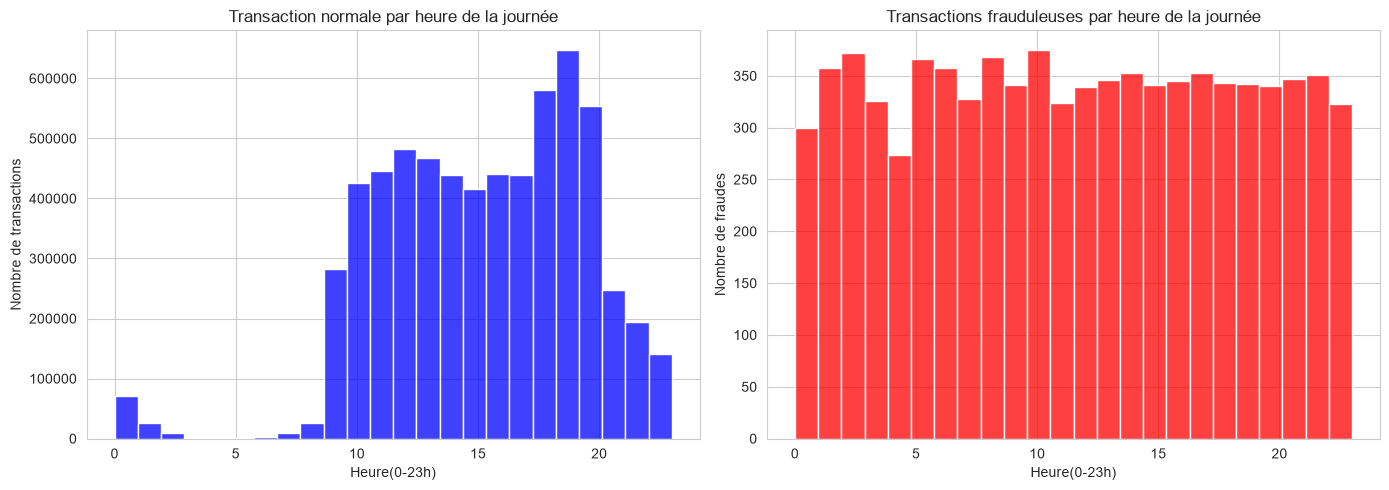

In [38]:
fraud_data['hour']= fraud_data['step']%24

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.histplot(data=fraud_data[fraud_data['isFraud']==0], x='hour', bins=24, color='blue', kde=False)
plt.title('Transaction normale par heure de la journée')
plt.xlabel('Heure(0-23h)')
plt.ylabel('Nombre de transactions')

plt.subplot(1,2,2)
sns.histplot(data=fraud_data[fraud_data['isFraud']==1], x='hour', bins=24, color='red', kde=False)
plt.title('Transactions frauduleuses par heure de la journée')
plt.xlabel('Heure(0-23h)')
plt.ylabel('Nombre de fraudes')

plt.tight_layout()
plt.show()


Au niveau de la tendance des transactions légitimes , on observe un creux dont une baisse des opérations entre 0h et 8h du matin et ensuite une hausse autour de 400000 autour de 10h à 20h! ce qui s'explique par le fait que les clients effectue leurs transactions majoritairement dans la journée et dorment la nuit jusqu'au matin réfletant la vie réelle.

Au niveau de la tendance des transactions frauduleuses , on observe un plafond tout au long de la journée contrairement aux graphiques bleus! On note constamment une oscillation entre 250 et 370 même la nuit.cela signifie que les transactions frauduleux sont gérées par des robots ou chatbots qui travaillent 24/24

On peut noté qu'il n'y a pas de réel corrélation entre le volume de transaction et le volume de fraude car entre 3h et 6h il n'y a pas de transaction mais il y'a autant de fraudes soit autour de 300. Ainsi la variable 'Step' ou 'Heure' ne permet d'éleminer la fraude mais elle montre que le ratio de fraude est plus élevé la nuit car il y a moins de transaction

Même si la fraude est répartie sur 24h, le contraste entre l'activité normale (qui s'arrête la nuit) et l'activité frauduleuse (qui continue la nuit) donne un signal comportemental utile pour repérer des anomalies contextuelles.

PREPARATION DE DONNEES

In [39]:
fraud_data= fraud_data[fraud_data['type'].isin(['CASH_OUT', 'TRANSFER'])].copy()
print("Nouvelle dimension du dataset:", fraud_data.shape)

Nouvelle dimension du dataset: (2770409, 14)


En filtrant les données pour ne conserver que les types de transactions dans lesquels des fraudes sont observées, nous passons de 6 millions à 2 millions de lignes. Cette opération permet d'alléger considérablement notre jeu de données.

Par ailleurs, le nombre de colonnes passe à 12, grâce à l'ajout de nouvelles variables créées lors de l'analyse exploratoire des données (EDA). Il s'agit notamment de `errorBalanceOrig`, `errorBalanceDest` et `hour`.

In [40]:
fraud_data.isnull().sum()

step                0
type                0
amount              0
nameOrig            0
oldbalanceOrg       0
newbalanceOrig      0
nameDest            0
oldbalanceDest      0
newbalanceDest      0
isFraud             0
isFlaggedFraud      0
errorBalanceOrig    0
errorBalanceDest    0
hour                0
dtype: int64

Notre base de données ne contient pas de valeur manquante

In [41]:
X= fraud_data.drop(columns=['nameOrig', 'nameDest', 'isFraud', 'isFlaggedFraud'])
X=pd.get_dummies(X, columns=['type'], drop_first=True)
y=fraud_data['isFraud']
print("Apercu des features (X):")
X.head()

Apercu des features (X):


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,hour,type_TRANSFER
2,1,181.00,181.0,0.0,0.0,0.00,0.00,181.0,1,True
3,1,181.00,181.0,0.0,21182.0,0.00,0.00,21363.0,1,False
15,1,229133.94,15325.0,0.0,5083.0,51513.44,213808.94,182703.5,1,False
19,1,215310.30,705.0,0.0,22425.0,0.00,214605.30,237735.3,1,True
24,1,311685.89,10835.0,0.0,6267.0,2719172.89,300850.89,-2401220.0,1,True


En supprimant nameOrig et nameDest nous evitons à notre modèle de faire du surapprentissage en mémorisant les numéros de compte au lieu de trouver les schémas de fraudes géneraux

Avec l'encodage de la variable categoricielle 'type' en valeur numerique ,nous empechons le modèle de planter car il ne peut pas lire les chaines de caractères

In [42]:
X_train, X_test, y_train, y_test= train_test_split(X,y , test_size=0.2, random_state=42, stratify=y)
print("Taille de X_train(entrainement):", X_train.shape)
print("Taille de X_test(test):", X_test.shape)

Taille de X_train(entrainement): (2216327, 10)
Taille de X_test(test): (554082, 10)


Nous avons séparer les données avec 80% pour l'entrainement et 20% pour le test tout en s'assurant d'avoir la même proportion de fraude dans les deux cas

In [43]:
model= LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
print("Entrainement du modèle en cours...")
model.fit(X_train, y_train)
print("Entrainement terminé.")

Entrainement du modèle en cours...
Entrainement terminé.


Une fois notre entrainement terminé , nous allons passé à l'évaluation de notre modèle.

In [44]:
y_pred= model.predict(X_test)
print("---Matrice de confusion---")
print(confusion_matrix(y_test, y_pred))

print("---Rapport de classification---")
print(classification_report(y_test, y_pred))


---Matrice de confusion---
[[521912  30527]
 [   146   1497]]
---Rapport de classification---
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    552439
           1       0.05      0.91      0.09      1643

    accuracy                           0.94    554082
   macro avg       0.52      0.93      0.53    554082
weighted avg       1.00      0.94      0.97    554082



Au niveau de la matrice de confusion on observe plusieurs cas:
1- le modèle identifie 521912 transactions légitimes comme telle sur les 552439 transactions légitmes en classant les 30527 comme frauduleux(ce qui n'est pas le cas)
2-Le modèle detecte au total 1497 transactions frauduleux sur les 1643 et considère 146 comme légitimes (ce qui n'est pas le cas)

Au niveau du rapport de classification
- Le modèle a une précision totale de 100% pour les transaction légitimes avec une detection de 94% conduisant à une moyenne harmonique f1-score de 0.97 (excellent)
- Le modèle a une precision de seulement 5% pour les transactions frauduleux avec un taux réel de detection de 91% . La moyenne harmonique entre le taux de precision et de détection est de 0.09
- Le modèle reussi 94% de ses prédictions. Mais celà est trompeur car notre dataset est remplie de transactions normales facile à deviner

Notre modèle actuel predit plus 30.000 fausses alertes pour 1497 réelles fraudes ; avec 5% de precision( sur 100 alertes seules 5 sont vraies), il faudrait plusieurs agents ou/et heures pour une banques ou fintech pour verifier manuellement les dossiers .
Pour reduire les fausses alertes , nous devrons reajuster notre seuil de précision avec un modèle non lineaire comme le random forest 

In [45]:
from lightgbm import LGBMClassifier
model_lgbm= LGBMClassifier(is_unbalance=True, random_state=42, n_estimators=100)
print("Entrainement du modèle LightGBM en cours...")
model_lgbm.fit(X_train, y_train)
print("Entrainement terminé.")
y_pred_lgbm= model_lgbm.predict(X_test)
print("---Matrice de confusion LightGBM---")
print(confusion_matrix(y_test, y_pred_lgbm))

print("---Rapport de classification LightGBM---")
print(classification_report(y_test, y_pred_lgbm))

Entrainement du modèle LightGBM en cours...
[LightGBM] [Info] Number of positive: 6570, number of negative: 2209757
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.113779 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2066
[LightGBM] [Info] Number of data points in the train set: 2216327, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.002964 -> initscore=-5.818124
[LightGBM] [Info] Start training from score -5.818124
Entrainement terminé.
---Matrice de confusion LightGBM---
[[549889   2550]
 [    19   1624]]
---Rapport de classification LightGBM---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    552439
           1       0.39      0.99      0.56      1643

    accuracy                           1.00    554082
   macro avg       0.69      0.99      0.78

Au niveau de la matrice de confusion du modèle LightGBM, on observe les résultats suivants :

1) Le modèle identifie correctement 549 889 transactions légitimes sur un total de 552 439. Il classe toutefois 2 550 transactions légitimes comme frauduleuses. Ce nombre reste relativement faible au regard du volume total des transactions.

2) Sur les 1 642 transactions frauduleuses, le modèle en détecte 1 497. Il classe seulement 19 transactions frauduleuses comme légitimes, ce qui représente une proportion très faible.

Avec ce nouveau modèle, nous observons une nette amélioration des performances.

- Pour les transactions légitimes, le modèle conserve une précision de 100 %, avec un taux de décision de 100 %. Le F1-score atteint également 1.
- Pour les transactions frauduleuses, la précision est de 39 %, avec un taux de décision de 99 %. Le F1-score, qui représente la moyenne harmonique entre la précision et le rappel, atteint 0,56.

Avec une précision de 39 %, environ 4 alertes sur 10 sont désormais des fraudes avérées, rendant le traitement manuel viable pour les équipes de contrôle.
En capturant 99 % des fraudes, le risque financier est minimal. De plus, en évitant de bloquer inutilement des dizaines de milliers de clients honnêtes, on protège l'expérience utilisateur et la fluidité des paiements.

--- Importance des features LightGBM---
            Feature  Importance
0              step         475
1            amount         411
2     oldbalanceOrg         385
7  errorBalanceDest         374
5    newbalanceDest         367
4    oldbalanceDest         357
6  errorBalanceOrig         265
3    newbalanceOrig         192
8              hour         150
9     type_TRANSFER          24


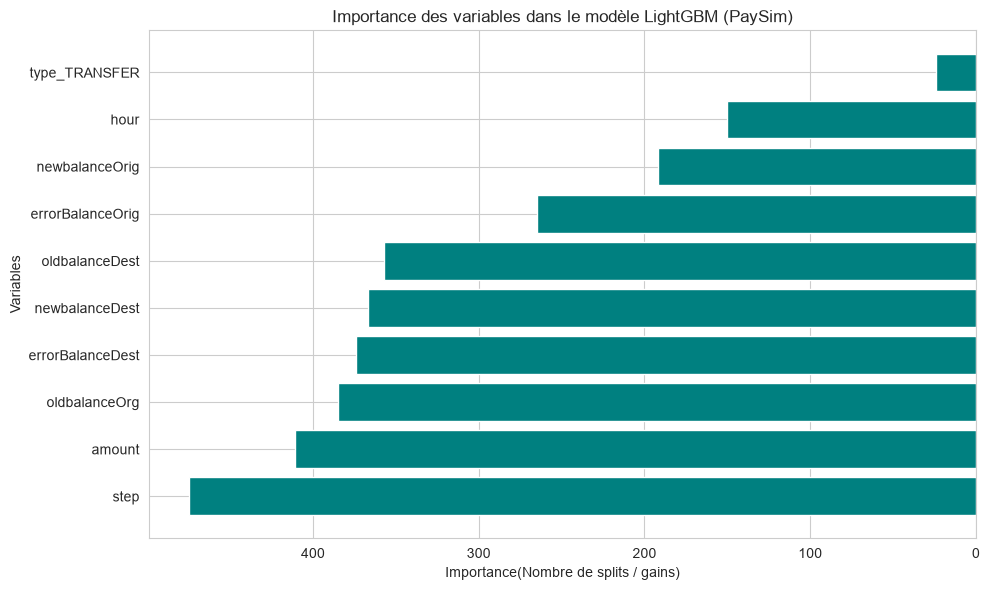

In [46]:
importance_df = pd.DataFrame({
    'Feature': X_train.columns,  
    'Importance': model_lgbm.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("--- Importance des features LightGBM---")
print(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color= 'teal')
plt.xlabel('Importance(Nombre de splits / gains)')
plt.ylabel('Variables')
plt.title('Importance des variables dans le modèle LightGBM (PaySim)')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

Les variables de soldes et d’erreurs de soldes occupent une place centrale, ce qui confirme la pertinence de la cohérence arithmétique des flux comme signal de fraude. Deux réserves méthodologiques s’imposent :
• Ces scores correspondent vraisemblablement au nombre de séparations (split count), mesure par défaut de LightGBM : leur somme (3 000) est compatible avec 100 arbres de 30 séparations. Cette mesure favorise les variables continues à forte cardinalité et sous-estime les variables binaires comme type_TRANSFER. Une importance par gain ou des valeurs SHAP donneraient une lecture plus fiable de la contribution réelle de chaque variable.
• La première place de step appelle de la prudence : dans un jeu de données simulé, cette variable peut refléter un artefact du simulateur et nuire à la généralisation sur des données réelles


DEPLOIEMENT DU MODELE 